# Evaluación grupal — Proyecto de Minería de Datos (Fases 1 a 4 de CRISP-DM)
**Impacto del incremento del diésel en SOBOCE S.A. · Entrega: `h3_03_evaluacion1_grupal_proyecto_crisp.ipynb`**

*Integrantes: Wara Jhoseany Callejas Mullisaca · Isabel Belen Castillo Miranda · Arnold Rodrigo Villa Lopez · Abril Michelle Cayllagua Marca · Daniel Gustavo Zambrana Rondon*

Este cuaderno responde, en orden, las **diez preguntas** de la evaluación. Cada respuesta es breve y va acompañada de la evidencia ejecutada (tablas y gráficos con título, unidades y fuente).

| Bloque | Preguntas |
|---|---|
| Entendimiento del negocio | P1, P2 |
| Entendimiento y preparación de los datos | P3, P4 |
| Exploración | P5 |
| Modelado (regresión logística **y** árbol de decisión) | P6 a P10 |

> **Criterio de redacción.** Se distingue siempre entre **resultados medidos** (calculados aquí con los datos) y **metas o propuestas** (por ejemplo, la meta de 78.5 Bs/Ton), que *no* se presentan como logros. Los datos son **sintéticos** (ver P3), por lo que las conclusiones describen el comportamiento de esa base, no de SOBOCE en la realidad.

### Carga de datos y configuración

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 10})
RANDOM_STATE = 42
FUENTE = "Fuente: base sintética SOBOCE (Impacto_Diesel_Cementera_SOBOCE.xlsx), elaboración propia."

def fuente(fig, texto=FUENTE):
    """Agrega la fuente al pie de cada gráfico."""
    fig.text(0.01, -0.01, texto, fontsize=8, color="gray", ha="left")

CANDIDATAS = [
    "Impacto_Diesel_Cementera_SOBOCE (2).xlsx",
    "Impacto_Diesel_Cementera_SOBOCE__2_.xlsx",
    "Data/Impacto_Diesel_Cementera_SOBOCE (2).xlsx",
    "/mnt/user-data/uploads/Impacto_Diesel_Cementera_SOBOCE__2_.xlsx",
]
RUTA = next((r for r in CANDIDATAS if os.path.exists(r)), None)
assert RUTA is not None, "No se encontró el .xlsx: súbelo o corrige la lista CANDIDATAS."
print("Archivo de datos:", RUTA)

df = pd.read_excel(RUTA)
# KPI del proyecto a nivel de fila (lote)
df["CDO_Ton"] = df["Costo_Diesel_Total_Bs"] / df["Volumen_Produccion_Ton"]
REG = {"Único (subsidiado)": "1. Subsidiado",
       "Segmentado (ULS+ industrial)": "2. ULS+ industrial",
       "Único (post-subsidio)": "3. DS 5516 (Bs 9.80/L)",
       "Segmentado (DS 5676 - precio internacional)": "4. DS 5676 (Bs ~18/L)"}
df["Regimen"] = df["Categoria_Precio_Diesel"].map(REG)

Archivo de datos: Impacto_Diesel_Cementera_SOBOCE (2).xlsx


---
# ENTENDIMIENTO DEL NEGOCIO
## P1. Problema, decisión que apoya y criterio de éxito

**Problema.** Desde la eliminación del subsidio al diésel (DS 5516) y la creación del segmento de grandes consumidores (DS 5676, agosto de 2026), el diésel de SOBOCE pasó de Bs 3.75/L a ≈ Bs 18/L. Se desconoce **cuánto sube el costo operativo del combustible por tonelada de cemento y en qué lotes se concentra**.

**Decisión o acción que apoya.** Ayudar a la gerencia de operaciones y finanzas a **identificar qué lotes (plantas, rutas, distancias) concentran el costo del diésel** para priorizar dónde actuar (rutas, carga, sustitución energética). El análisis *no ejecuta* esas acciones: aporta la evidencia para decidirlas.

**A quién afecta.** A SOBOCE (rentabilidad de sus 3 plantas: Viacha, El Puente y Warnes), a los transportistas que distribuyen el cemento y, indirectamente, al consumidor por el precio de la bolsa de 50 kg (el mercado tiene un techo de absorción de precios).

**Criterio de éxito.**
- *De negocio (meta futura, no medida):* reducir el costo del diésel por tonelada bajo el DS 5676 de **102.85 a 78.5 Bs/Ton (−23.7 %)** en 6 meses, según el documento de Fase 1. Ninguna acción se ha implementado, por lo que **no se reporta mejora**.
- *Del análisis (criterio fijado por el grupo para esta entrega):* un modelo de clasificación que detecte los lotes críticos con **recall ≥ 0.90** y **F1 ≥ 0.85** en datos de prueba. Se verifica en P9.

**Conexión.** El modelo convierte el costo por tonelada en una pregunta accionable —¿este lote será crítico?— y explica por qué (distancia, precio), que son los factores sobre los que la empresa puede, o no, actuar.

---
## P2. Métrica principal y su cálculo

**Métrica:** *Costo del Diésel Operativo por Tonelada producida* (**CDO_Ton**). Es una **métrica de negocio** (no de desempeño del modelo; las métricas del modelo —accuracy, precision, recall, F1— se usan en P9).

$$CDO\_Ton = \frac{(Consumo\_Diesel\_Maquinaria\_L + Consumo\_Diesel\_Transporte\_L)\times Precio\_Diesel\_Aplicado\_Bs\_L}{Volumen\_Produccion\_Ton} = \frac{Costo\_Diesel\_Total\_Bs}{Volumen\_Produccion\_Ton}$$

| Variable | Unidad |
|---|---|
| Consumo de diésel (maquinaria y transporte) | litros (L) |
| Precio diésel aplicado | bolivianos por litro (Bs/L) |
| Volumen de producción | toneladas (Ton) |
| **CDO_Ton** | **bolivianos por tonelada (Bs/Ton)** |

**Valor observado hasta ahora** (calculado abajo): promedio de **21.92 Bs/Ton** con precio subsidiado y **102.85 Bs/Ton** bajo el DS 5676 (n = 34 lotes).

,lotes,precio_bs_l,consumo_l,volumen_ton,CDO_Ton_promedio,CDO_Ton_mediana
Regimen,,,,,,
1. Subsidiado,9027.000000,3.75,"15,049.98","2,572.69",21.92,21.31
2. ULS+ industrial,213.000000,8.79,"14,727.04","2,509.96",51.54,49.58
3. DS 5516 (Bs 9.80/L),726.000000,9.82,"14,830.84","2,526.54",57.49,56.60
4. DS 5676 (Bs ~18/L),34.000000,18.14,"16,109.32","2,832.99",102.85,101.81
Todos los registros,10000.000000,4.35,"15,030.80","2,568.89",25.41,22.20



Baseline DS 5676 (n = 34 lotes)
  Promedio de CDO_Ton por lote (definición de la métrica) : 102.85 Bs/Ton
  Cociente de promedios (costo medio / volumen medio)      : 103.17 Bs/Ton
  Componente maquinaria  : 29.98 Bs/Ton
  Componente transporte  : 72.87 Bs/Ton
  Meta del proyecto (NO medida, objetivo futuro): 78.50 Bs/Ton


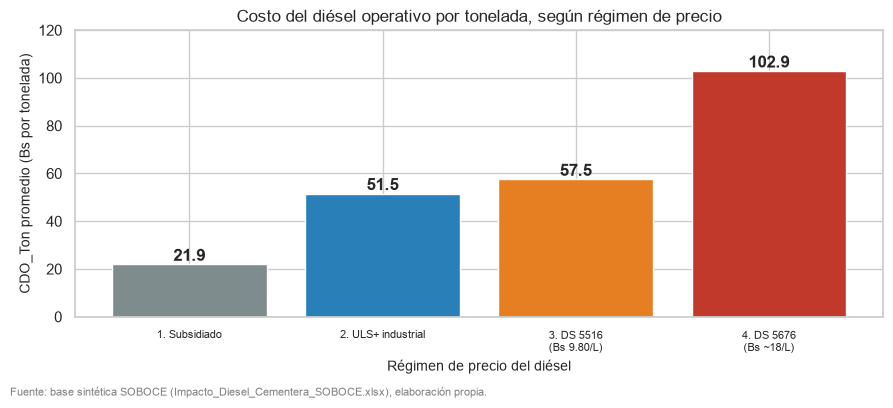

In [3]:
# ---- Métrica de negocio: CDO_Ton (Bs/Ton) ----
# CDO_Ton = Costo_Diesel_Total_Bs / Volumen_Produccion_Ton
#         = (Consumo_Maquinaria_L + Consumo_Transporte_L) x Precio_Aplicado_Bs_L / Volumen_Produccion_Ton
tabla_kpi = (df.groupby("Regimen")
    .agg(lotes=("CDO_Ton", "size"),
         precio_bs_l=("Precio_Diesel_Aplicado_SOBOCE_Bs_Litro", "mean"),
         consumo_l=("Consumo_Diesel_Total_L", "mean"),
         volumen_ton=("Volumen_Produccion_Ton", "mean"),
         CDO_Ton_promedio=("CDO_Ton", "mean"),
         CDO_Ton_mediana=("CDO_Ton", "median"))
    .round(2))
tabla_kpi.loc["Todos los registros"] = [len(df), df["Precio_Diesel_Aplicado_SOBOCE_Bs_Litro"].mean(),
    df["Consumo_Diesel_Total_L"].mean(), df["Volumen_Produccion_Ton"].mean(),
    df["CDO_Ton"].mean(), df["CDO_Ton"].median()]
tabla_kpi = tabla_kpi.round(2)
display(tabla_kpi.style.set_caption("Tabla 1. CDO_Ton observado por régimen de precio del diésel (Bs/Ton). Fuente: base SOBOCE")
        .format("{:,.2f}", subset=tabla_kpi.columns[1:]))

# Baseline bajo DS 5676: dos formas de calcularlo (deben leerse con cuidado)
b = df[df["Regimen"].str.startswith("4.")]
print(f"\nBaseline DS 5676 (n = {len(b)} lotes)")
print(f"  Promedio de CDO_Ton por lote (definición de la métrica) : {b['CDO_Ton'].mean():.2f} Bs/Ton")
print(f"  Cociente de promedios (costo medio / volumen medio)      : {b['Costo_Diesel_Total_Bs'].mean() / b['Volumen_Produccion_Ton'].mean():.2f} Bs/Ton")
print(f"  Componente maquinaria  : {(b['Consumo_Diesel_Maquinaria_L']*b['Precio_Diesel_Aplicado_SOBOCE_Bs_Litro']/b['Volumen_Produccion_Ton']).mean():.2f} Bs/Ton")
print(f"  Componente transporte  : {(b['Consumo_Diesel_Transporte_L']*b['Precio_Diesel_Aplicado_SOBOCE_Bs_Litro']/b['Volumen_Produccion_Ton']).mean():.2f} Bs/Ton")
print("  Meta del proyecto (NO medida, objetivo futuro): 78.50 Bs/Ton")

fig, ax = plt.subplots(figsize=(9, 4))
orden = sorted(df["Regimen"].unique())
vals = df.groupby("Regimen")["CDO_Ton"].mean().reindex(orden)
ax.bar(range(4), vals.values, color=["#7f8c8d", "#2980b9", "#e67e22", "#c0392b"])
ax.set_xticks(range(4)); ax.set_xticklabels([o.replace(" (", "\n(") for o in orden], fontsize=8)
for i, v_ in enumerate(vals.values): ax.text(i, v_ + 1.5, f"{v_:.1f}", ha="center", fontweight="bold")
ax.set_ylabel("CDO_Ton promedio (Bs por tonelada)"); ax.set_xlabel("Régimen de precio del diésel")
ax.set_title("Costo del diésel operativo por tonelada, según régimen de precio"); ax.set_ylim(0, 120)
fuente(fig); plt.tight_layout(); plt.show()

**Lectura de la métrica.**
- El CDO_Ton promedio sube de **21.92** (subsidiado) a **57.49** (DS 5516) y **102.85 Bs/Ton** (DS 5676): ≈ **+369 %** entre el primer y el último régimen. El gráfico muestra que el salto sigue al del precio (3.75 → 9.82 → 18.14 Bs/L).
- Con DS 5676 el costo se compone de ≈ 30 Bs/Ton de maquinaria y ≈ 73 Bs/Ton de transporte (≈ 71 %).
- *Nota de consistencia:* el documento de Fase 1 obtiene 102.85 como cociente 292,269.26 / 2,832.99, que en realidad da 103.17. El valor 102.85 es el **promedio del CDO_Ton por lote**, que es la definición de la métrica; se usa ese. Los componentes del documento (30.01 y 72.84) difieren en ±0.03 de los recalculados aquí.
- *Meta:* 78.5 Bs/Ton es un **objetivo futuro**, no un resultado.

**Acción concreta para mejorarla (propuesta, aún no evaluada):** reasignar los despachos de **más de 180 km** —los que el modelo de P10 marca como críticos aun con precio subsidiado— a la planta más cercana o a cargas consolidadas. Es una hipótesis a validar con datos reales; en este trabajo **no se mide su efecto**.

---
# ENTENDIMIENTO Y PREPARACIÓN DE LOS DATOS
## P3. Unidad de análisis, origen y tamaño

- **Unidad de análisis / una fila:** un **lote diario de producción y despacho de una planta** (planta-día), con su región de destino, tipo de cemento y régimen de precio.
- **Origen:** microdatos **sintéticos** generados con reglas estadísticas y anclados a precios del diésel, tipos de cambio e hitos regulatorios reales de Bolivia (DS 5516 y DS 5676), según la ficha técnica del documento de Fase 1. **No son registros internos de SOBOCE.**
- **Tamaño:** **10,000 registros × 31 variables**, del 13-jul-2017 al 28-ago-2026, con 3 plantas, 8 regiones de destino y 3 tipos de cemento.
- **Filtros:** ninguno; se usan los 10,000 registros.

In [4]:
print("Unidad de análisis: 1 fila = 1 lote diario de producción/despacho de una planta (planta-día) con una región de destino")
print(f"Registros: {df.shape[0]:,} | Variables originales: {df.shape[1] - 2} (+ CDO_Ton y Regimen creadas)")
print(f"Rango de fechas: {pd.to_datetime(df['Fecha']).min().date()} a {pd.to_datetime(df['Fecha']).max().date()}")
print("Filtros aplicados: ninguno -> registros usados:", len(df))
print()
resumen = pd.DataFrame({
    "Plantas": [df["Planta"].nunique()], "Destinos": [df["Region_Destino"].nunique()],
    "Tipos de cemento": [df["Tipo_Cemento"].nunique()], "Regímenes de precio": [df["Regimen"].nunique()]})
display(resumen.style.hide(axis="index").set_caption("Tabla 2. Dimensiones del conjunto de datos"))
display(df["Planta"].value_counts().rename("lotes").to_frame().style.set_caption("Tabla 3. Lotes por planta"))

Unidad de análisis: 1 fila = 1 lote diario de producción/despacho de una planta (planta-día) con una región de destino
Registros: 10,000 | Variables originales: 31 (+ CDO_Ton y Regimen creadas)
Rango de fechas: 2017-07-13 a 2026-08-28
Filtros aplicados: ninguno -> registros usados: 10000



Plantas,Destinos,Tipos de cemento,Regímenes de precio
3,8,3,4


,lotes
Planta,
Viacha (La Paz),3334
El Puente (Tarija),3333
Warnes (Santa Cruz),3333


---
## P4. Problemas de calidad y preparación aplicada

**Valores faltantes:** **0 columnas** con nulos (0 celdas vacías de 310,000). **Duplicados:** 0 filas y 0 IDs repetidos. Se verificaron además las relaciones internas del dato (la Tabla 4 resume cada comprobación y la decisión tomada).

In [5]:
# ---- 1) Valores faltantes ----
orig = df.drop(columns=["CDO_Ton", "Regimen"])   # solo las 31 columnas originales
nulos = orig.isna().sum()
print(f"Columnas con valores faltantes: {(nulos > 0).sum()} de {orig.shape[1]} | Celdas vacías: {int(nulos.sum())} de {orig.size:,}")
# ---- 2) Duplicados ----
print(f"Filas duplicadas (completas): {orig.duplicated().sum()} | IDs repetidos: {orig['ID'].duplicated().sum()}")

# ---- 3) Inconsistencias internas (se verifican con cálculo, no a ojo) ----
tc = (df["Consumo_Diesel_Maquinaria_L"] + df["Consumo_Diesel_Transporte_L"] - df["Consumo_Diesel_Total_L"]).abs() > 0.2
cc = (df["Consumo_Diesel_Total_L"] * df["Precio_Diesel_Aplicado_SOBOCE_Bs_Litro"] / df["Costo_Diesel_Total_Bs"] - 1).abs() > 0.01
cu = (df["Costo_Diesel_Total_Bs"] / df["Tipo_Cambio_Oficial_BOB_USD"] / df["Costo_Diesel_Total_USD"] - 1).abs() > 0.01
vp = df["Volumen_Ventas_Ton"] > df["Volumen_Produccion_Ton"]
tp = df["Tipo_Cambio_Paralelo_BOB_USD"] < df["Tipo_Cambio_Oficial_BOB_USD"]
q1, q3 = df["CDO_Ton"].quantile([.25, .75]); lim = q3 + 1.5 * (q3 - q1)
out = df["CDO_Ton"] > lim
constantes = [c for c in df.columns if df[c].nunique() == 1]
n_ds5676 = int((df["Regimen"].str.startswith("4.")).sum())

chequeos = pd.DataFrame([
    ["Consumo total ≠ maquinaria + transporte", int(tc.sum()), "Sin problema"],
    ["Costo diésel ≠ litros × precio (> 1 %)", int(cc.sum()), "Sin problema"],
    ["Costo en USD ≠ Bs / tipo de cambio oficial (> 1 %)", int(cu.sum()), "Sin problema"],
    ["Ventas > producción en el mismo lote", int(vp.sum()), "Se conserva: la diferencia es de ±7 % (posible inventario); no se usa Volumen_Ventas"],
    ["Tipo de cambio paralelo < oficial", int(tp.sum()), "Se conserva: variable no utilizada en el modelo"],
    ["Valores atípicos de CDO_Ton (regla IQR)", int(out.sum()), f"Se conservan: {out[df['Regimen'].str.startswith(('3','4'))].sum()} son de regímenes post-subsidio (el fenómeno estudiado)"],
    [f"Columnas constantes: {', '.join(constantes)}", len(constantes), "Se excluyen (no aportan información)"],
    ["Fecha almacenada como texto", 1, "Se convierte a datetime"],
    ["Registros del DS 5676: documento Fase 1 dice 341", n_ds5676, f"La base tiene {n_ds5676}; el documento debe corregirse (9027+213+726+{n_ds5676} = {9027+213+726+n_ds5676})"],
], columns=["Verificación", "Filas / columnas afectadas", "Decisión"])
display(chequeos.style.hide(axis="index").set_caption("Tabla 4. Verificaciones de calidad de datos y decisión tomada"))

# ---- Preparación aplicada ----
df["Fecha"] = pd.to_datetime(df["Fecha"])
print("\nPreparación aplicada: (1) Fecha -> datetime; (2) no se imputó ni eliminó ninguna fila (0 nulos, 0 duplicados);"
      " (3) columnas constantes excluidas del modelado; (4) valores atípicos conservados; (5) codificación y escalado dentro de un Pipeline (ver P7).")

Columnas con valores faltantes: 0 de 31 | Celdas vacías: 0 de 310,000
Filas duplicadas (completas): 0 | IDs repetidos: 0


Verificación,Filas / columnas afectadas,Decisión
Consumo total ≠ maquinaria + transporte,0,Sin problema
Costo diésel ≠ litros × precio (> 1 %),0,Sin problema
Costo en USD ≠ Bs / tipo de cambio oficial (> 1 %),0,Sin problema
Ventas > producción en el mismo lote,2234,Se conserva: la diferencia es de ±7 % (posible inventario); no se usa Volumen_Ventas
Tipo de cambio paralelo < oficial,9,Se conserva: variable no utilizada en el modelo
Valores atípicos de CDO_Ton (regla IQR),766,Se conservan: 615 son de regímenes post-subsidio (el fenómeno estudiado)
"Columnas constantes: Pais, Empresa, Categoria_Consumidor_Diesel",3,Se excluyen (no aportan información)
Fecha almacenada como texto,1,Se convierte a datetime
Registros del DS 5676: documento Fase 1 dice 341,34,La base tiene 34; el documento debe corregirse (9027+213+726+34 = 10000)



Preparación aplicada: (1) Fecha -> datetime; (2) no se imputó ni eliminó ninguna fila (0 nulos, 0 duplicados); (3) columnas constantes excluidas del modelado; (4) valores atípicos conservados; (5) codificación y escalado dentro de un Pipeline (ver P7).


**Qué se hizo y por qué.**
- **Sin imputación ni eliminación de filas:** no hay nulos ni duplicados, así que no hay nada que corregir.
- **Coherencia interna correcta:** consumo total = maquinaria + transporte, costo = litros × precio y costo en USD = Bs / tipo de cambio se cumplen en las 10,000 filas.
- **Inconsistencias relevantes, conservadas con justificación:** ventas > producción en 2,234 lotes (diferencia de hasta ±7 %, compatible con inventarios; la variable no se usa en el modelo); 9 filas con tipo de cambio paralelo menor que el oficial (variable no usada).
- **Valores atípicos del KPI (766 por regla IQR):** se **conservan**; 615 pertenecen a regímenes post-subsidio y son justamente el fenómeno que se estudia. Eliminarlos borraría el efecto del decreto.
- **Columnas constantes** (`Pais`, `Empresa`, `Categoria_Consumidor_Diesel`): se excluyen del modelado.
- **Fecha como texto:** se convierte a `datetime`.
- **Error del documento detectado:** el documento de Fase 1 indica 341 registros bajo el DS 5676, pero la base tiene **34** (9,027 + 213 + 726 + 34 = 10,000). Debe corregirse en el documento.

---
# EXPLORACIÓN DE LOS DATOS
## P5. Hallazgo principal de la exploración

**Hallazgo:** el CDO_Ton fue **estable (≈ 21–23 Bs/Ton) durante ocho años** y **se multiplicó** con los cambios de precio; además, **dentro de cada régimen crece linealmente con la distancia de transporte**.

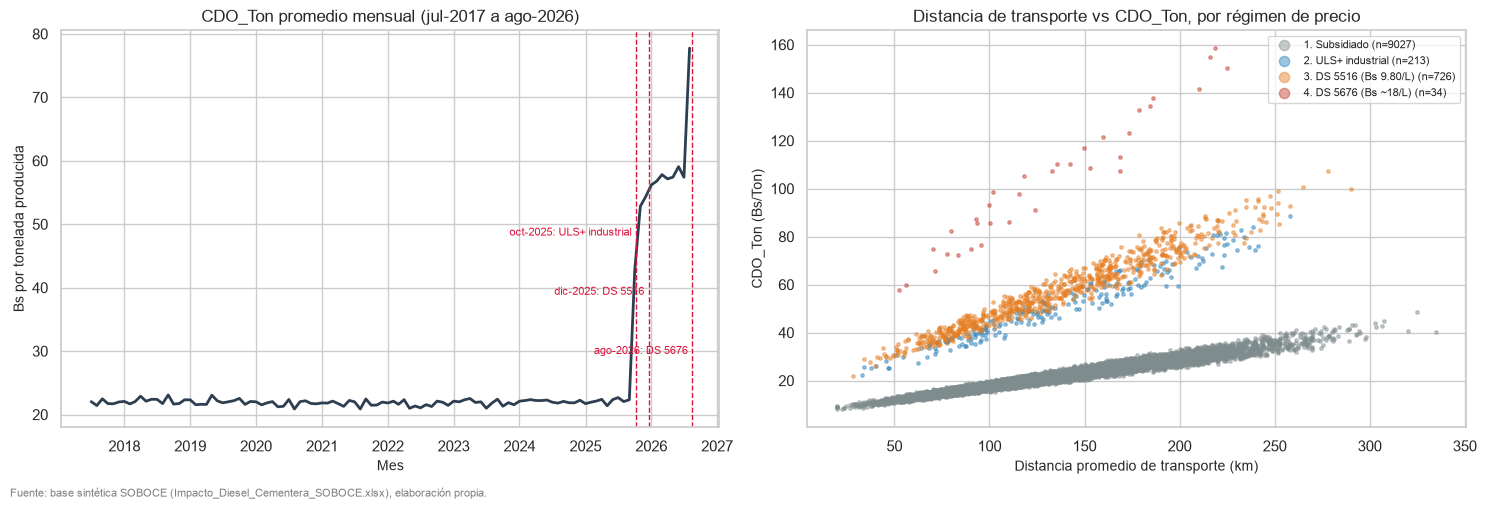

Correlación distancia – CDO_Ton, solo régimen subsidiado: 0.976
Planta con mayor CDO_Ton promedio: {'El Puente (Tarija)': 31.2, 'Viacha (La Paz)': 19.3, 'Warnes (Santa Cruz)': 25.7}


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (a) Evolución mensual del KPI
mensual = df.set_index("Fecha")["CDO_Ton"].resample("MS").mean()
axes[0].plot(mensual.index, mensual.values, color="#2c3e50", lw=2)
for fecha, txt, alt in [("2025-10-08", "oct-2025: ULS+ industrial", .62), ("2025-12-18", "dic-2025: DS 5516", .50), ("2026-08-17", "ago-2026: DS 5676", .38)]:
    axes[0].axvline(pd.Timestamp(fecha), color="crimson", ls="--", lw=1)
    axes[0].text(pd.Timestamp(fecha) - pd.Timedelta(days=25), mensual.max() * alt, txt, color="crimson", fontsize=8, ha="right")
axes[0].set_title("CDO_Ton promedio mensual (jul-2017 a ago-2026)")
axes[0].set_xlabel("Mes"); axes[0].set_ylabel("Bs por tonelada producida")

# (b) Distancia vs CDO_Ton por régimen
paleta = dict(zip(sorted(df["Regimen"].unique()), ["#7f8c8d", "#2980b9", "#e67e22", "#c0392b"]))
for r, g in df.groupby("Regimen"):
    axes[1].scatter(g["Distancia_Prom_Transporte_Km"], g["CDO_Ton"], s=6, alpha=.45, color=paleta[r], label=f"{r} (n={len(g)})")
axes[1].set_title("Distancia de transporte vs CDO_Ton, por régimen de precio")
axes[1].set_xlabel("Distancia promedio de transporte (km)"); axes[1].set_ylabel("CDO_Ton (Bs/Ton)")
axes[1].legend(markerscale=3, fontsize=8)
fuente(fig); plt.tight_layout(); plt.show()

print("Correlación distancia – CDO_Ton, solo régimen subsidiado:",
      round(df.loc[df["Regimen"].str.startswith("1."), ["Distancia_Prom_Transporte_Km", "CDO_Ton"]].corr().iloc[0, 1], 3))
print("Planta con mayor CDO_Ton promedio:", df.groupby("Planta")["CDO_Ton"].mean().round(1).to_dict())

**Lectura de los gráficos.**
- *Izquierda (evolución mensual):* entre 2017 y sep-2025 el promedio mensual se mantiene entre 20.9 y 23.1 Bs/Ton. En oct-2025 salta a 42.7, se ubica alrededor de **57 Bs/Ton** en 2026 y llega a **77.7 Bs/Ton** en ago-2026, con el DS 5676.
- *Derecha (distancia vs CDO_Ton):* cada régimen forma una «banda» propia; la banda se **desplaza hacia arriba** con el precio y **su pendiente aumenta**, es decir, el precio multiplica el costo de cada kilómetro. Bajo el subsidio la correlación distancia–CDO_Ton es **0.976**.
- *Por planta:* El Puente (distancia media 180 km) tiene el CDO_Ton promedio más alto (31.2 Bs/Ton), seguido de Warnes (139 km; 25.7) y Viacha (91 km; 19.3).

**Por qué importa:** muestra que el impacto del decreto es grande y **que las rutas largas lo amplifican**; justifica usar **precio y distancia** como variables explicativas y plantear la clasificación de lotes críticos. *Es un patrón descriptivo; no controla otros factores ni prueba causalidad.*

---
# MODELADO
## P6. Variable objetivo, clases y modelos

- **Variable objetivo:** `ALTO_CDO` (binaria).
  - **Clase 0 — lote normal:** CDO_Ton ≤ percentil 75 de entrenamiento.
  - **Clase 1 — lote crítico:** CDO_Ton > percentil 75 de entrenamiento.
- **Por qué el percentil 75:** la meta de 78.5 Bs/Ton solo la superan ~1 % de los lotes (clases casi vacías); con P75 hay ≈ 25 % de lotes críticos, suficiente para entrenar y evaluar.
- **Modelos usados (ambos vistos en clase):** **regresión logística** y **árbol de decisión**, con los mismos datos y la misma partición para poder compararlos.
- **Por qué son pertinentes:** el resultado es binario y la gerencia necesita *explicaciones*. La regresión logística entrega **probabilidades y coeficientes** (cuánto pesa cada variable); el árbol entrega **reglas «si… entonces…»** con umbrales (p. ej., «más de X km») fáciles de comunicar.
- **Variables:** numéricas (precio del diésel, distancia, volumen de producción, horas de maquinaria, nº de vehículos) y categóricas (planta, región de destino, tipo de cemento). Se **excluyen** las variables que forman parte del KPI o son su consecuencia (fuga de información) y las colineales con el precio.

Variable objetivo: ALTO_CDO  (clasificación binaria)
  Clase 0 = lote normal : CDO_Ton <= P75 de los datos de ENTRENAMIENTO
  Clase 1 = lote crítico: CDO_Ton >  P75 de los datos de ENTRENAMIENTO

Variables numéricas : ['Precio_Diesel_Aplicado_SOBOCE_Bs_Litro', 'Distancia_Prom_Transporte_Km', 'Volumen_Produccion_Ton', 'Horas_Operacion_Maquinaria', 'Num_Vehiculos_Transporte']
Variables categóricas: ['Planta', 'Region_Destino', 'Tipo_Cemento']

Excluidas por fuga de información (son parte del KPI o su consecuencia): Consumo_Diesel_*, Costo_Diesel_*, Costo_Transporte_Bs_Ton, Costo_Produccion_Bs_Ton, Emisiones_CO2_Ton, Margen_Bruto_Pct, CDO_Ton
Excluidas por colinealidad con el precio: Inflacion_Mensual_Pct, Tipo_Cambio_*, otros precios de diésel


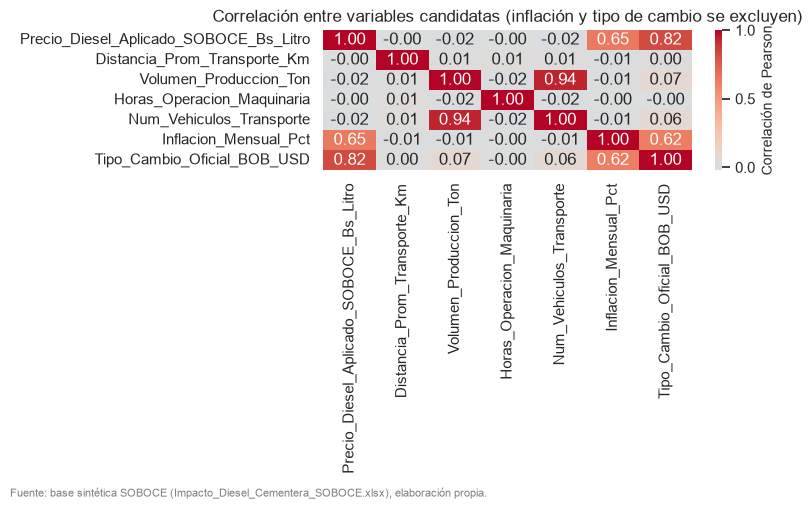

In [7]:
# Variable objetivo (se construye en P7, después de separar train/test, para no usar datos de prueba)
print("Variable objetivo: ALTO_CDO  (clasificación binaria)")
print("  Clase 0 = lote normal : CDO_Ton <= P75 de los datos de ENTRENAMIENTO")
print("  Clase 1 = lote crítico: CDO_Ton >  P75 de los datos de ENTRENAMIENTO")

NUM = ["Precio_Diesel_Aplicado_SOBOCE_Bs_Litro", "Distancia_Prom_Transporte_Km", "Volumen_Produccion_Ton",
       "Horas_Operacion_Maquinaria", "Num_Vehiculos_Transporte"]
CAT = ["Planta", "Region_Destino", "Tipo_Cemento"]
print("\nVariables numéricas :", NUM)
print("Variables categóricas:", CAT)
print("\nExcluidas por fuga de información (son parte del KPI o su consecuencia): Consumo_Diesel_*, Costo_Diesel_*, "
      "Costo_Transporte_Bs_Ton, Costo_Produccion_Bs_Ton, Emisiones_CO2_Ton, Margen_Bruto_Pct, CDO_Ton")
print("Excluidas por colinealidad con el precio: Inflacion_Mensual_Pct, Tipo_Cambio_*, otros precios de diésel")

plt.figure(figsize=(8, 5))
cols = NUM + ["Inflacion_Mensual_Pct", "Tipo_Cambio_Oficial_BOB_USD"]
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, cbar_kws={"label": "Correlación de Pearson"})
plt.title("Correlación entre variables candidatas (inflación y tipo de cambio se excluyen)")
fuente(plt.gcf()); plt.tight_layout(); plt.show()

**Lectura.** Las variables elegidas son prácticamente independientes entre sí (correlaciones cercanas a 0), salvo `Inflacion_Mensual_Pct` y `Tipo_Cambio_Oficial`, que se mueven junto con el precio del diésel y por eso se excluyen.

---
## P7. Entrenamiento y prueba: proporción, método y control de fugas

- **Proporción:** **80 % entrenamiento (8,000 lotes) / 20 % prueba (2,000 lotes).**
- **Método:** `train_test_split` **estratificado por régimen de precio** (así los 4 regímenes aparecen en ambas particiones) con `random_state = 42` (reproducible).
- **Cómo se evitó que la prueba influyera en el entrenamiento:**
  1. La separación se hace **antes** de crear las clases: el **umbral P75 se calcula solo con entrenamiento** (27.88 Bs/Ton; con todos los datos sería 27.85).
  2. Escalado y codificación se **ajustan solo con entrenamiento**, dentro de un `Pipeline`.
  3. La validación cruzada (5 pliegues) y la búsqueda de hiperparámetros usan **solo entrenamiento**.
  4. El conjunto de prueba se usa **una vez**, al final, para evaluar.

In [8]:
# Separación 80/20, estratificada por régimen de precio (garantiza que los 4 regímenes estén en train y test)
df_train, df_test = train_test_split(df, test_size=0.20, stratify=df["Regimen"], random_state=RANDOM_STATE)

# El umbral de la variable objetivo se calcula SOLO con entrenamiento (así la prueba no influye en la definición de las clases)
UMBRAL = df_train["CDO_Ton"].quantile(0.75)
for d in (df_train, df_test):
    d["ALTO_CDO"] = (d["CDO_Ton"] > UMBRAL).astype(int)

X_train, y_train = df_train[NUM + CAT], df_train["ALTO_CDO"]
X_test,  y_test  = df_test[NUM + CAT],  df_test["ALTO_CDO"]

print(f"Umbral P75 (solo entrenamiento): {UMBRAL:.2f} Bs/Ton  | P75 de todos los datos: {df['CDO_Ton'].quantile(.75):.2f} Bs/Ton")
print(f"Entrenamiento: {len(X_train):,} filas (80 %) | Prueba: {len(X_test):,} filas (20 %) | random_state = {RANDOM_STATE}")
dist = pd.DataFrame({
    "Entrenamiento": [len(y_train), (y_train == 0).sum(), (y_train == 1).sum(), y_train.mean() * 100],
    "Prueba":        [len(y_test),  (y_test == 0).sum(),  (y_test == 1).sum(),  y_test.mean() * 100]},
    index=["Total de lotes", "Clase 0 (normal)", "Clase 1 (crítico)", "% clase 1"]).round(1)
display(dist.style.set_caption("Tabla 5. Distribución de clases en entrenamiento y prueba").format("{:,.1f}"))

cv_reg = pd.crosstab(df_train["Regimen"], "train").join(pd.crosstab(df_test["Regimen"], "prueba"))
display(cv_reg.style.set_caption("Tabla 6. Lotes por régimen en cada partición"))

Umbral P75 (solo entrenamiento): 27.88 Bs/Ton  | P75 de todos los datos: 27.85 Bs/Ton
Entrenamiento: 8,000 filas (80 %) | Prueba: 2,000 filas (20 %) | random_state = 42


,Entrenamiento,Prueba
Total de lotes,"8,000.0","2,000.0"
Clase 0 (normal),"6,000.0","1,514.0"
Clase 1 (crítico),"2,000.0",486.0
% clase 1,25.0,24.3


col_0,train,prueba
Regimen,,
1. Subsidiado,7222,1805
2. ULS+ industrial,170,43
3. DS 5516 (Bs 9.80/L),581,145
4. DS 5676 (Bs ~18/L),27,7


**Lectura.** En entrenamiento hay 25.0 % de lotes críticos y en prueba 24.3 %: proporciones similares. El régimen DS 5676 tiene solo **7 lotes en prueba**, por lo que cualquier conclusión específica sobre ese régimen es limitada.

### Entrenamiento de los modelos (base de P8, P9 y P10)
Para cada modelo se entrena primero la versión **por defecto** y luego una versión **ajustada** con `GridSearchCV` (5 pliegues, métrica F1, solo entrenamiento). En el árbol se ajustan criterio, profundidad máxima, mínimo de muestras por hoja y balanceo de clases; en la regresión logística, la regularización `C`, el tipo de penalización y el balanceo de clases.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Preprocesadores: se ajustan SOLO con los datos de entrenamiento dentro del Pipeline
prep_lr = ColumnTransformer([("num", StandardScaler(), NUM),
                             ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT)])
prep_dt = ColumnTransformer([("num", "passthrough", NUM),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

# ---------------- Árbol de decisión ----------------
dt_def = Pipeline([("prep", prep_dt), ("m", DecisionTreeClassifier(random_state=RANDOM_STATE))]).fit(X_train, y_train)
dt_grid = GridSearchCV(
    Pipeline([("prep", prep_dt), ("m", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    {"m__criterion": ["gini", "entropy"], "m__max_depth": [2, 3, 4, 5, 6, 8, 10],
     "m__min_samples_leaf": [1, 10, 30, 60], "m__class_weight": [None, "balanced"]},
    cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
# Regla del error estándar (1-SE): entre las configuraciones cuyo F1 de validación cruzada está dentro de 1 error
# estándar del mejor, se elige la más simple (menor profundidad, mayor tamaño mínimo de hoja). Es el criterio clásico
# para elegir árboles más pequeños, estables y legibles sin perder desempeño.
cvr = pd.DataFrame(dt_grid.cv_results_)
i_best = cvr["mean_test_score"].idxmax()
se = cvr.loc[i_best, "std_test_score"] / np.sqrt(cv.get_n_splits())
cand = cvr[cvr["mean_test_score"] >= cvr.loc[i_best, "mean_test_score"] - se]
elegida = cand.sort_values(["param_m__max_depth", "param_m__min_samples_leaf"], ascending=[True, False]).iloc[0]
dt = Pipeline([("prep", prep_dt), ("m", DecisionTreeClassifier(random_state=RANDOM_STATE))]).set_params(**elegida["params"]).fit(X_train, y_train)
print("Mejor F1 CV bruto:", {k.split("__")[1]: v for k, v in dt_grid.best_params_.items()}, f"F1 CV = {dt_grid.best_score_:.4f}")

# ---------------- Regresión logística ----------------
lr_def = Pipeline([("prep", prep_lr), ("m", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]).fit(X_train, y_train)
lr_grid = GridSearchCV(
    Pipeline([("prep", prep_lr), ("m", LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE))]),
    {"m__C": [0.01, 0.1, 1, 10, 100], "m__penalty": ["l1", "l2"], "m__class_weight": [None, "balanced"]},
    cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
lr = lr_grid.best_estimator_

print("Árbol por defecto -> profundidad:", dt_def.named_steps["m"].get_depth(), "| hojas:", dt_def.named_steps["m"].get_n_leaves())
print("Árbol ajustado (regla 1-SE) ->", {k.split("__")[1]: v for k, v in elegida["params"].items()}, f"| F1 CV = {elegida['mean_test_score']:.4f} ± {elegida['std_test_score']:.4f}")
print(f"Árbol ajustado -> profundidad: {dt.named_steps['m'].get_depth()} | hojas: {dt.named_steps['m'].get_n_leaves()}")
print("Reg. logística ajustada ->", {k.split("__")[1]: v for k, v in lr_grid.best_params_.items()}, f"| F1 CV = {lr_grid.best_score_:.4f}")

Mejor F1 CV bruto: {'class_weight': None, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 60} F1 CV = 0.8989
Árbol por defecto -> profundidad: 23 | hojas: 346
Árbol ajustado (regla 1-SE) -> {'class_weight': None, 'criterion': 'gini', 'max_depth': 2, 'min_samples_leaf': 60} | F1 CV = 0.8962 ± 0.0140
Árbol ajustado -> profundidad: 2 | hojas: 4
Reg. logística ajustada -> {'C': 1, 'class_weight': 'balanced', 'penalty': 'l2'} | F1 CV = 0.8970


**Lectura.**
- **Árbol por defecto:** crece hasta **23 niveles y 346 hojas** y acierta el 100 % en entrenamiento, pero baja a 93.4 % en prueba → **sobreajuste**.
- **Árbol ajustado:** se aplicó la regla del error estándar (entre configuraciones con F1 equivalente se elige la más simple). Resultado: `gini`, **profundidad 2**, mínimo 60 muestras por hoja, **4 hojas**, con F1 de validación 0.896 ± 0.014 (el mejor valor bruto, 0.899, usaba 8 niveles y no era legible; la diferencia es menor que el error de validación).
- **Regresión logística ajustada:** `C = 1`, penalización L2, clases balanceadas (F1 de validación 0.897). El modelo por defecto ya rinde casi igual: el problema es muy simple para este tipo de modelo.

## P8. Variables más importantes y cómo se determinó

**Cómo se determinó la importancia** (tres evidencias complementarias):
1. **Árbol:** importancia por reducción de impureza (`feature_importances_`).
2. **Regresión logística:** coeficientes de variables **estandarizadas** (comparables entre sí) y sus *odds ratios*.
3. **Permutación en el conjunto de prueba (ambos modelos):** cuánto cae el F1 al desordenar una variable; es independiente del tipo de modelo.

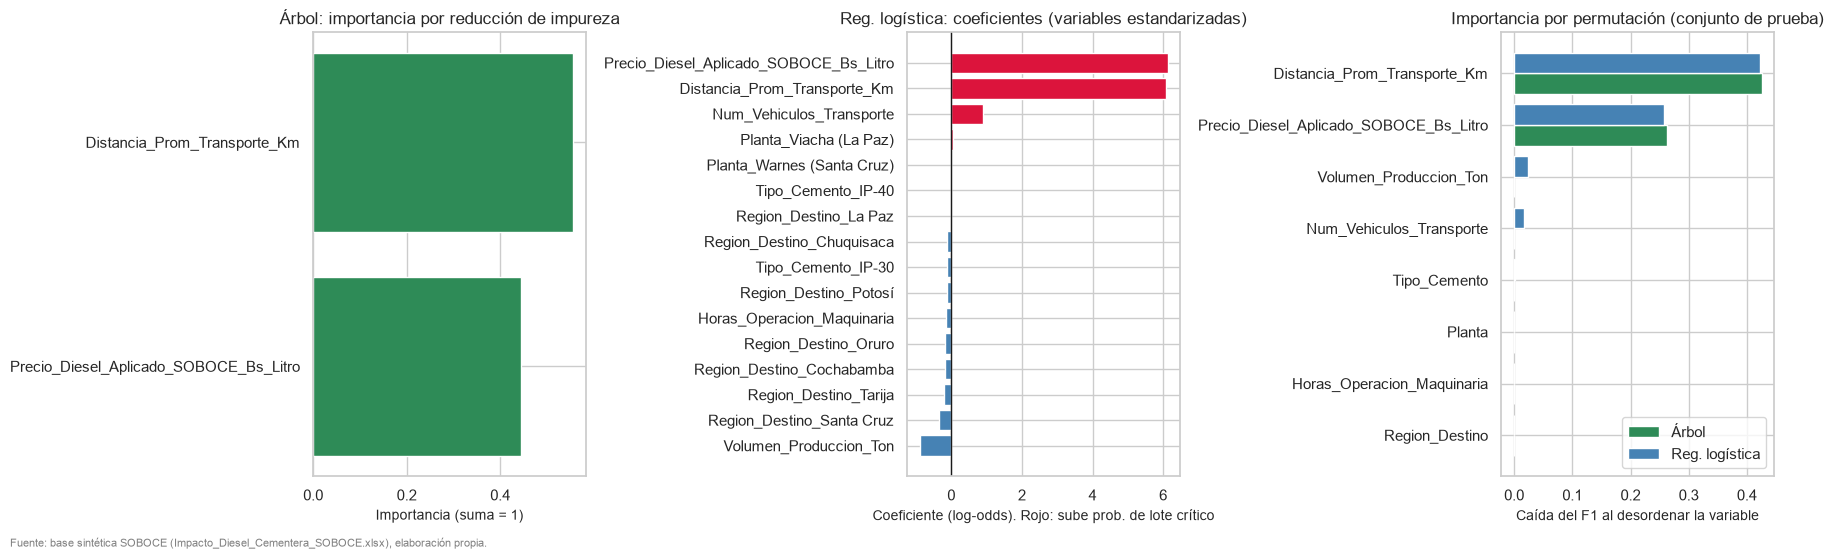

,Importancia árbol
Distancia_Prom_Transporte_Km,0.5556
Precio_Diesel_Aplicado_SOBOCE_Bs_Litro,0.4444


,Árbol,Reg. logística
Distancia_Prom_Transporte_Km,0.4252,0.4223
Precio_Diesel_Aplicado_SOBOCE_Bs_Litro,0.2624,0.2568
Volumen_Produccion_Ton,0.0000,0.0240
Num_Vehiculos_Transporte,0.0000,0.0162
Tipo_Cemento,0.0000,0.0011
Planta,0.0000,0.0006
Horas_Operacion_Maquinaria,0.0000,0.0003
Region_Destino,0.0000,-0.0009


,odds ratio (por 1 DE o vs categoría base)
Precio_Diesel_Aplicado_SOBOCE_Bs_Litro,457.957000
Distancia_Prom_Transporte_Km,443.673000
Num_Vehiculos_Transporte,2.489000
Planta_Viacha (La Paz),1.053000
Planta_Warnes (Santa Cruz),1.004000
Tipo_Cemento_IP-40,0.987000
Region_Destino_La Paz,0.982000
Region_Destino_Chuquisaca,0.889000
Tipo_Cemento_IP-30,0.877000
Region_Destino_Potosí,0.877000


In [10]:
nom_dt = [n.split("__")[1] for n in dt.named_steps["prep"].get_feature_names_out()]
nom_lr = [n.split("__")[1] for n in lr.named_steps["prep"].get_feature_names_out()]

imp_dt = pd.Series(dt.named_steps["m"].feature_importances_, index=nom_dt)
coef_lr = pd.Series(lr.named_steps["m"].coef_[0], index=nom_lr)

# Importancia por permutación (sobre PRUEBA): cuánto cae el F1 al desordenar cada variable original
pi_dt = permutation_importance(dt, X_test, y_test, scoring="f1", n_repeats=10, random_state=RANDOM_STATE)
pi_lr = permutation_importance(lr, X_test, y_test, scoring="f1", n_repeats=10, random_state=RANDOM_STATE)
perm = pd.DataFrame({"Árbol": pi_dt.importances_mean, "Reg. logística": pi_lr.importances_mean}, index=NUM + CAT).assign(_t=lambda d: d.sum(axis=1)).sort_values("_t", ascending=False).drop(columns="_t")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
s = imp_dt[imp_dt > 0].sort_values()
axes[0].barh(s.index, s.values, color="seagreen")
axes[0].set_title("Árbol: importancia por reducción de impureza"); axes[0].set_xlabel("Importancia (suma = 1)")
c = coef_lr.sort_values()
axes[1].barh(c.index, c.values, color=["crimson" if v > 0 else "steelblue" for v in c.values])
axes[1].axvline(0, color="k", lw=1)
axes[1].set_title("Reg. logística: coeficientes (variables estandarizadas)"); axes[1].set_xlabel("Coeficiente (log-odds). Rojo: sube prob. de lote crítico")
p = perm.iloc[::-1]
y_ = np.arange(len(p)); axes[2].barh(y_ - .2, p["Árbol"], .4, label="Árbol", color="seagreen")
axes[2].barh(y_ + .2, p["Reg. logística"], .4, label="Reg. logística", color="steelblue")
axes[2].set_yticks(y_); axes[2].set_yticklabels(p.index); axes[2].legend()
axes[2].set_title("Importancia por permutación (conjunto de prueba)"); axes[2].set_xlabel("Caída del F1 al desordenar la variable")
fuente(fig); plt.tight_layout(); plt.show()

tabla_imp = pd.DataFrame({"Importancia árbol": imp_dt[imp_dt > 0].sort_values(ascending=False)})
display(tabla_imp.style.set_caption("Tabla 7. Importancias del árbol ajustado (variables con importancia > 0)").format("{:.4f}"))
display(perm.round(4).style.set_caption("Tabla 8. Importancia por permutación en prueba (caída promedio del F1, 10 repeticiones)").format("{:.4f}"))
odds = np.exp(coef_lr).sort_values(ascending=False).round(3).to_frame("odds ratio (por 1 DE o vs categoría base)")
display(odds.style.set_caption("Tabla 9. Odds ratios de la regresión logística"))

**Resultado.** Las dos variables más importantes en ambos modelos son la **distancia de transporte** y el **precio del diésel**:
- **Árbol:** distancia 0.556 y precio 0.444; las demás variables tienen importancia 0.
- **Permutación:** al desordenar la distancia el F1 cae ≈ 0.42 (árbol 0.425; regresión logística 0.422) y con el precio ≈ 0.26 (0.262 y 0.257). Las demás variables caen menos de 0.03.
- **Regresión logística (coeficientes estandarizados):** precio ≈ +6.1 y distancia ≈ +6.1 (odds ratios ≈ 458 y ≈ 444 por cada desviación estándar); número de vehículos ≈ +0.9 (odds ratio 2.5) y **volumen de producción ≈ −0.9** (odds ratio 0.41). Planta, destino y tipo de cemento tienen efectos cercanos a 0.

**Interpretación de una variable (sin atribuir causalidad).** La **distancia** es la variable más asociada con que un lote sea crítico: los lotes de más de ≈ 180 km tienen mucha mayor probabilidad de superar el umbral. Es coherente con que el diésel de transporte crece casi en proporción a la distancia (correlación 0.92 entre distancia y litros de transporte en estos datos), pero el modelo solo muestra **asociación**: no demuestra que acortar rutas reduciría el costo, ni controla factores no medidos (tipo de camión, carga, estado de las vías). Además, los datos son sintéticos, así que esta relación refleja cómo se construyó la base.

*Precaución:* los *odds ratios* de precio y distancia son enormes porque ambas variables separan casi perfectamente las clases; se leen como «efecto dominante», no como cifras exactas.

## P9. Desempeño en el conjunto de prueba

Se evalúan los dos modelos **en los mismos 2,000 lotes de prueba**. Referencia: un modelo que siempre responda «normal» tendría **75.7 %** de accuracy (1,514 de 2,000 lotes).

,Accuracy (train),Accuracy (prueba),Precision,Recall,F1,ROC-AUC
Modelo,,,,,,
Árbol por defecto,1.000,0.934,0.869,0.860,0.865,0.909
Árbol ajustado,0.945,0.953,0.859,0.963,0.908,0.974
Reg. logística por defecto,0.949,0.953,0.922,0.879,0.900,0.993
Reg. logística ajustada,0.946,0.951,0.856,0.957,0.904,0.993


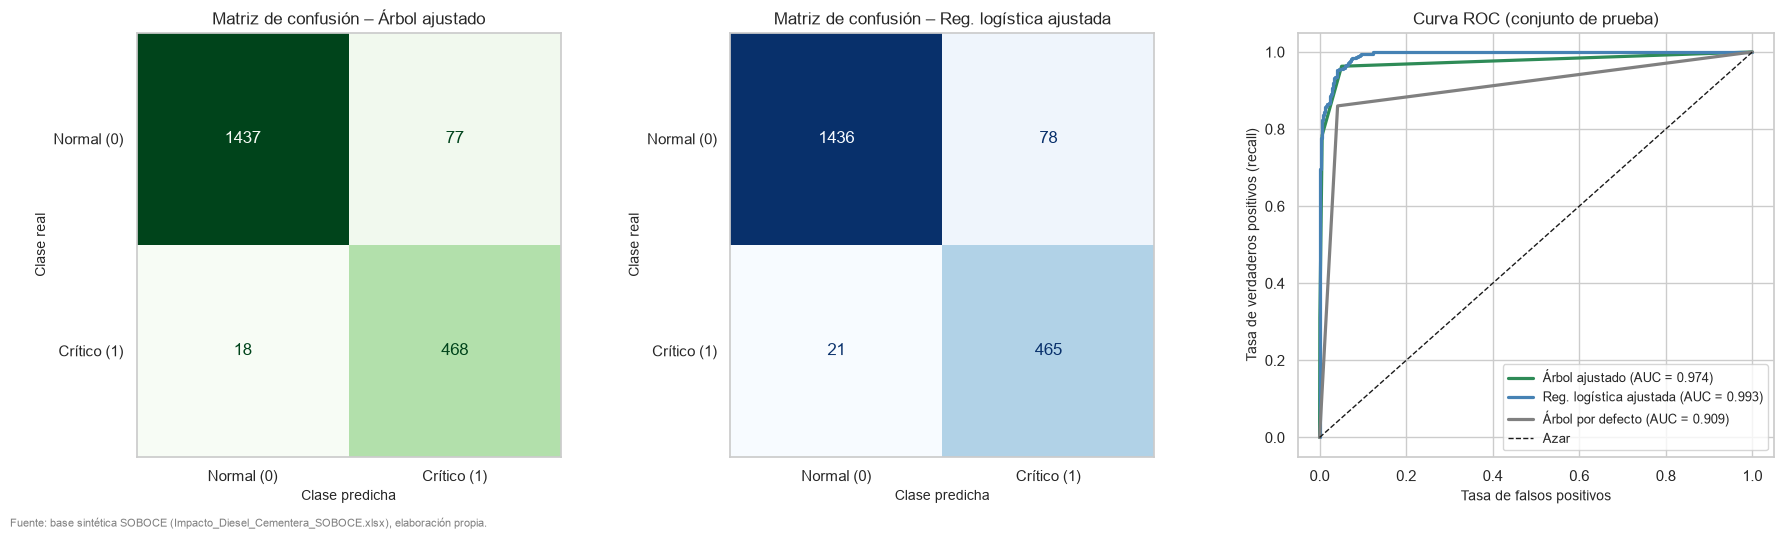

Árbol ajustado: TN=1437 | FP (falsa alarma)=77 | FN (lote crítico no detectado)=18 | TP=468
Reg. logística ajustada: TN=1436 | FP (falsa alarma)=78 | FN (lote crítico no detectado)=21 | TP=465


In [11]:
def metricas(nombre, mdl):
    pt, pr = mdl.predict(X_test), mdl.predict_proba(X_test)[:, 1]
    return {"Modelo": nombre, "Accuracy (train)": accuracy_score(y_train, mdl.predict(X_train)),
            "Accuracy (prueba)": accuracy_score(y_test, pt), "Precision": precision_score(y_test, pt),
            "Recall": recall_score(y_test, pt), "F1": f1_score(y_test, pt), "ROC-AUC": roc_auc_score(y_test, pr)}

tabla = pd.DataFrame([metricas("Árbol por defecto", dt_def), metricas("Árbol ajustado", dt),
                      metricas("Reg. logística por defecto", lr_def), metricas("Reg. logística ajustada", lr)]).set_index("Modelo")
display(tabla.style.format("{:.3f}").set_caption("Tabla 10. Desempeño en el conjunto de prueba (n = %d lotes)" % len(y_test)))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.3))
for ax, (nombre, mdl, cmap) in zip(axes[:2], [("Árbol ajustado", dt, "Greens"), ("Reg. logística ajustada", lr, "Blues")]):
    cm_ = confusion_matrix(y_test, mdl.predict(X_test))
    ConfusionMatrixDisplay(cm_, display_labels=["Normal (0)", "Crítico (1)"]).plot(ax=ax, cmap=cmap, colorbar=False, values_format="d")
    ax.set_title(f"Matriz de confusión – {nombre}"); ax.set_xlabel("Clase predicha"); ax.set_ylabel("Clase real"); ax.grid(False)
for nombre, mdl, col in [("Árbol ajustado", dt, "seagreen"), ("Reg. logística ajustada", lr, "steelblue"), ("Árbol por defecto", dt_def, "gray")]:
    pr = mdl.predict_proba(X_test)[:, 1]; f, t, _ = roc_curve(y_test, pr)
    axes[2].plot(f, t, lw=2.3, color=col, label=f"{nombre} (AUC = {roc_auc_score(y_test, pr):.3f})")
axes[2].plot([0, 1], [0, 1], "k--", lw=1, label="Azar"); axes[2].legend(loc="lower right", fontsize=9)
axes[2].set_title("Curva ROC (conjunto de prueba)"); axes[2].set_xlabel("Tasa de falsos positivos"); axes[2].set_ylabel("Tasa de verdaderos positivos (recall)")
fuente(fig); plt.tight_layout(); plt.show()

for nombre, mdl in [("Árbol ajustado", dt), ("Reg. logística ajustada", lr)]:
    tn, fp, fn, tp = confusion_matrix(y_test, mdl.predict(X_test)).ravel()
    print(f"{nombre}: TN={tn} | FP (falsa alarma)={fp} | FN (lote crítico no detectado)={fn} | TP={tp}")

**Resultados (prueba, n = 2,000).**

| Modelo ajustado | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|
| Árbol de decisión (profundidad 2) | 0.953 | 0.859 | 0.963 | 0.908 | 0.974 |
| Regresión logística | 0.951 | 0.856 | 0.957 | 0.904 | 0.993 |

- **Matrices de confusión:** árbol → TN 1,437 · FP 77 · FN 18 · TP 468; regresión logística → TN 1,436 · FP 78 · FN 21 · TP 465.
- Ambos modelos superan el 75.7 % de la línea base y **cumplen el criterio fijado en P1** (recall ≥ 0.90 y F1 ≥ 0.85).
- **Comparación:** la diferencia entre ambos es de **3 lotes críticos** de 486 en el recall, un margen que no permite afirmar que uno sea mejor. La regresión logística ordena mejor por riesgo (AUC 0.993 vs 0.974), porque el árbol de 4 hojas produce solo cuatro probabilidades distintas.
- **Árbol por defecto:** 100 % en entrenamiento y 93.4 % en prueba (F1 = 0.865): peor generalización que el ajustado.

**¿Qué error es más importante reducir?** El **falso negativo** (un lote crítico que el modelo declara normal). El objetivo del proyecto es ubicar dónde se concentra el costo del diésel; un falso negativo deja ese costo sin atender. Un falso positivo solo implica revisar un lote de más. Por eso se prioriza el **recall** (0.96 con el árbol; 0.96 con la regresión logística).

## P10. Visualización de cómo decide el modelo

Se muestra **el árbol entrenado** (con texto legible y sus reglas en texto) y, para la regresión logística, **cuánto contribuye cada variable a la predicción de un lote concreto**.

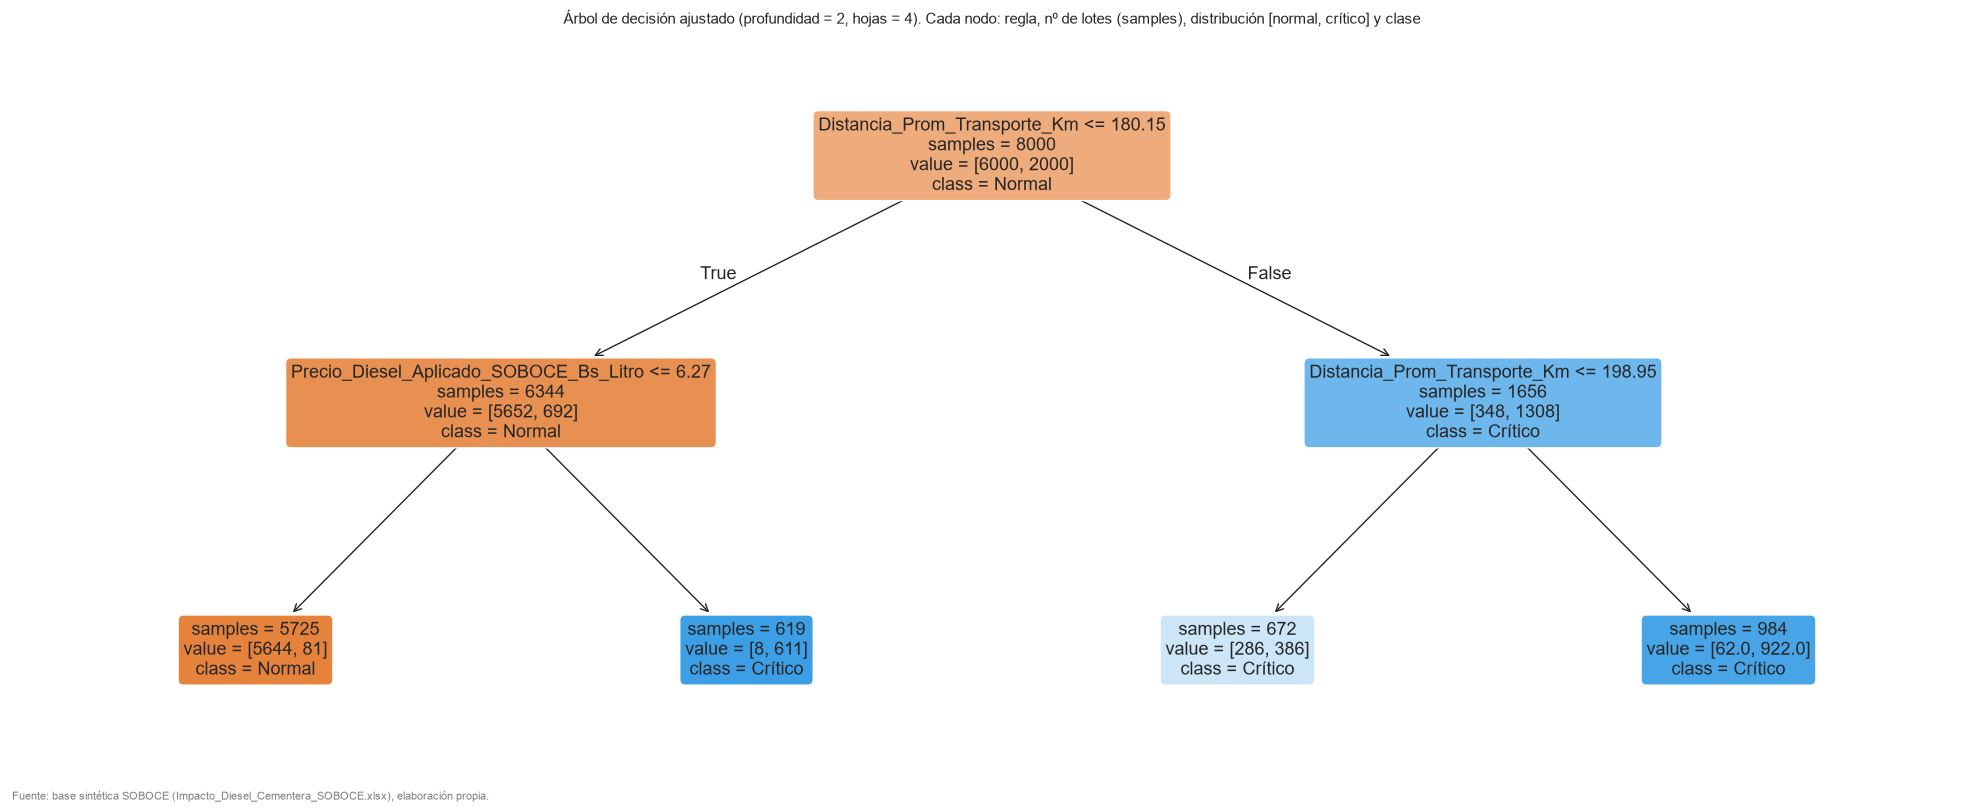

|--- Distancia_Prom_Transporte_Km <= 180.15
|   |--- Precio_Diesel_Aplicado_SOBOCE_Bs_Litro <= 6.27
|   |   |--- weights: [5644.00, 81.00] class: 0
|   |--- Precio_Diesel_Aplicado_SOBOCE_Bs_Litro >  6.27
|   |   |--- weights: [8.00, 611.00] class: 1
|--- Distancia_Prom_Transporte_Km >  180.15
|   |--- Distancia_Prom_Transporte_Km <= 198.95
|   |   |--- weights: [286.00, 386.00] class: 1
|   |--- Distancia_Prom_Transporte_Km >  198.95
|   |   |--- weights: [62.00, 922.00] class: 1

Lote de ejemplo: {'Planta': 'El Puente (Tarija)', 'Region_Destino': 'Chuquisaca', 'Distancia_Prom_Transporte_Km': 269.6, 'Precio_Diesel_Aplicado_SOBOCE_Bs_Litro': 3.76}
CDO_Ton real = 37.8 Bs/Ton (umbral = 27.9)  -> ruta en el árbol:
  Distancia_Prom_Transporte_Km = 269.60 > 180.15
  Distancia_Prom_Transporte_Km = 269.60 > 198.95
  => hoja: clase predicha = Crítico
Prob. predicha de lote crítico (reg. logística): 1.000 | (árbol): 0.937


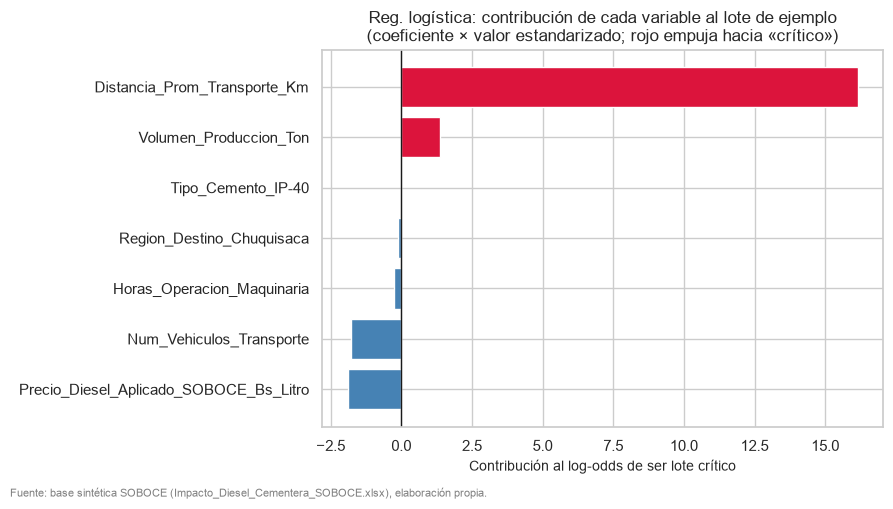

In [12]:
modelo_dt = dt.named_steps["m"]
fig = plt.figure(figsize=(20, 8))
plot_tree(modelo_dt, feature_names=nom_dt, class_names=["Normal", "Crítico"], filled=True, rounded=True,
          fontsize=13, impurity=False, proportion=False)
plt.title(f"Árbol de decisión ajustado (profundidad = {modelo_dt.get_depth()}, hojas = {modelo_dt.get_n_leaves()}). "
          "Cada nodo: regla, nº de lotes (samples), distribución [normal, crítico] y clase", fontsize=11)
fuente(fig); plt.tight_layout(); plt.show()

print(export_text(modelo_dt, feature_names=nom_dt, show_weights=True))

# ---- Ruta de decisión de un lote real de la muestra de prueba ----
idx = np.where((y_test.values == 1) & (df_test["Regimen"].str.startswith("1.").values))[0][0]
fila = X_test.iloc[[idx]]
Xt = dt.named_steps["prep"].transform(fila); Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
nodos = modelo_dt.decision_path(Xt).indices
print("Lote de ejemplo:", fila[["Planta", "Region_Destino", "Distancia_Prom_Transporte_Km", "Precio_Diesel_Aplicado_SOBOCE_Bs_Litro"]].iloc[0].to_dict())
print(f"CDO_Ton real = {df_test.iloc[idx]['CDO_Ton']:.1f} Bs/Ton (umbral = {UMBRAL:.1f})  -> ruta en el árbol:")
for n in nodos:
    if modelo_dt.tree_.children_left[n] == modelo_dt.tree_.children_right[n]:
        print(f"  => hoja: clase predicha = {['Normal', 'Crítico'][int(modelo_dt.tree_.value[n][0].argmax())]}")
    else:
        f_, th = nom_dt[modelo_dt.tree_.feature[n]], modelo_dt.tree_.threshold[n]
        v_ = Xt[0, modelo_dt.tree_.feature[n]]
        print(f"  {f_} = {v_:.2f} {'<=' if v_ <= th else '>'} {th:.2f}")

# ---- Regresión logística: contribución de cada variable a ESE lote ----
zt = lr.named_steps["prep"].transform(fila); zt = zt.toarray() if hasattr(zt, "toarray") else zt
contrib = pd.Series(zt[0] * lr.named_steps["m"].coef_[0], index=nom_lr)
contrib = contrib[contrib.abs() > 1e-9].sort_values()
fig = plt.figure(figsize=(9, 5))
plt.barh(contrib.index, contrib.values, color=["crimson" if v > 0 else "steelblue" for v in contrib.values])
plt.axvline(0, color="k", lw=1)
plt.title("Reg. logística: contribución de cada variable al lote de ejemplo\n(coeficiente × valor estandarizado; rojo empuja hacia «crítico»)")
plt.xlabel("Contribución al log-odds de ser lote crítico")
print(f"Prob. predicha de lote crítico (reg. logística): {lr.predict_proba(fila)[0, 1]:.3f} | (árbol): {dt.predict_proba(fila)[0, 1]:.3f}")
fuente(plt.gcf()); plt.tight_layout(); plt.show()

**Interpretación de una ruta de decisión (árbol).** Un lote de **El Puente (Tarija) hacia Chuquisaca**, con **269.6 km** y diésel a **Bs 3.76/L** (precio subsidiado), sigue la ruta: *distancia > 180.15 km* → *distancia > 198.95 km* → **lote crítico**. En esa hoja, **922 de los 984 lotes de entrenamiento (93.7 %)** eran críticos, lo que coincide con la probabilidad que da el árbol (0.937). Su CDO_Ton real fue 37.8 Bs/Ton, sobre el umbral de 27.9.

**Reglas del árbol en lenguaje simple:**
1. Distancia ≤ 180 km y precio ≤ Bs 6.27/L → **normal** (5,644 normales frente a 81 críticos).
2. Distancia ≤ 180 km y precio > Bs 6.27/L → **crítico** (611 de 619). Todos los precios posteriores al subsidio superan ese umbral.
3. Distancia > 180 km → **crítico** en su mayoría (386 de 672 entre 180 y 199 km, que es la zona de duda; 922 de 984 sobre 199 km).

**Regresión logística (gráfico de contribuciones).** Para el mismo lote, casi todo el empuje hacia «crítico» proviene de la **distancia** (≈ +16 en log-odds). El **precio subsidiado** (por debajo del promedio de los datos) y el número de vehículos **restan** (≈ −2 cada uno). Con un precio cercano a Bs 18/L, la contribución del precio sería positiva y de gran magnitud.

**Qué aporta la visualización:** hace **auditable** el modelo: un gerente puede ver qué regla o variable llevó a la decisión y discutirla. Las reglas son *asociaciones aprendidas de los datos* y no relaciones causales.

---
## Cierre

### Resultados medidos y metas futuras

| Elemento | Estado | Valor |
|---|---|---|
| CDO_Ton promedio, régimen subsidiado | **Medido** | 21.92 Bs/Ton |
| CDO_Ton promedio, DS 5676 (n = 34) | **Medido** | 102.85 Bs/Ton |
| Rendimiento del árbol en prueba (F1 / recall) | **Medido** | 0.908 / 0.963 |
| Rendimiento de la regresión logística en prueba (F1 / recall) | **Medido** | 0.904 / 0.957 |
| Meta de CDO_Ton | **Meta futura, no alcanzada** | 78.5 Bs/Ton |
| Reducción del CDO_Ton por alguna acción | **No medida** (no se implementó ninguna) | — |

### Limitaciones
- **Datos sintéticos:** los patrones (dos variables explican casi todo) reflejan las reglas de generación y probablemente serían más complejos con datos reales.
- Solo 34 de 10,000 lotes corresponden al DS 5676 (7 en prueba): el modelo se evalúa sobre todo en el período subsidiado y en el post-subsidio anterior al decreto de agosto de 2026.
- La separación es aleatoria (estratificada); una validación **temporal** (entrenar con el pasado y probar con lo reciente) sería más exigente.
- «Crítico» se define por el percentil 75 del CDO_Ton, una decisión de negocio: otro umbral cambiaría las métricas.
- Los resultados muestran **asociaciones**, no causalidad.

### Correcciones pendientes en el documento de Fase 1
- Registros bajo el DS 5676: **34**, no 341.
- Baseline: 102.85 Bs/Ton es el promedio por lote; el cociente de promedios da 103.17 Bs/Ton.